In [85]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [86]:
df=pd.read_excel(r'C:\Users\DELL\Downloads\Financial_Sample.xlsx')

In [87]:
df.head(4)

,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Canada,Carretera,NaN,1618.5,3,20.0,32370.0,0.0,32370.0,16185.0,16185.0,2014-01-01,1,January,2014
1,Government,Germany,Carretera,NaN,1321.0,3,20.0,26420.0,0.0,26420.0,13210.0,13210.0,2014-01-01,1,January,2014
2,Midmarket,France,Carretera,NaN,2178.0,3,15.0,32670.0,0.0,32670.0,21780.0,10890.0,2014-06-01,6,June,2014
3,Midmarket,Germany,Carretera,NaN,888.0,3,15.0,13320.0,0.0,13320.0,8880.0,4440.0,2014-06-01,6,June,2014


In [88]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Segment              692 non-null    str           
 1   Country              689 non-null    str           
 2   Product              692 non-null    str           
 3   Discount Band        638 non-null    str           
 4   Units Sold           695 non-null    float64       
 5   Manufacturing Price  700 non-null    int64         
 6   Sale Price           693 non-null    float64       
 7   Gross Sales          695 non-null    float64       
 8   Discounts            695 non-null    float64       
 9    Sales               700 non-null    float64       
 10  COGS                 700 non-null    float64       
 11  Profit               700 non-null    float64       
 12  Date                 700 non-null    datetime64[us]
 13  Month Number         700 non-null    int64    

In [89]:
df.describe()

,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Year
count,695.000000,700.000000,693.000000,6.950000e+02,695.000000,7.000000e+02,700.000000,700.000000,700,700.000000,700.000000
mean,1607.880576,96.477143,117.914863,1.839670e+05,13077.162345,1.696091e+05,145475.211429,24133.860371,2014-04-28 21:36:00,7.900000,2013.750000
min,200.000000,3.000000,7.000000,1.799000e+03,0.000000,1.655080e+03,918.000000,-40617.500000,2013-09-01 00:00:00,1.000000,2013.000000
25%,906.500000,5.000000,12.000000,1.760250e+04,799.640000,1.592800e+04,7490.000000,2805.960000,2013-12-24 06:00:00,5.750000,2013.750000
50%,1540.000000,10.000000,20.000000,3.838500e+04,2567.600000,3.554020e+04,22506.250000,9242.200000,2014-05-16 12:00:00,9.000000,2014.000000
75%,2224.750000,250.000000,300.000000,2.859500e+05,15333.500000,2.610775e+05,245607.500000,22662.000000,2014-09-08 12:00:00,10.250000,2014.000000
max,4492.500000,260.000000,350.000000,1.207500e+06,149677.500000,1.159200e+06,950625.000000,262200.000000,2014-12-01 00:00:00,12.000000,2014.000000
std,867.307497,108.602612,136.571680,2.547749e+05,22993.148986,2.367263e+05,203865.506118,42760.626563,NaN,3.377321,0.433322


In [90]:
df.isnull().sum()

Segment                 8
Country                11
Product                 8
Discount Band          62
Units Sold              5
Manufacturing Price     0
Sale Price              7
Gross Sales             5
Discounts               5
 Sales                  0
COGS                    0
Profit                  0
Date                    0
Month Number            0
Month Name              0
Year                    0
dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

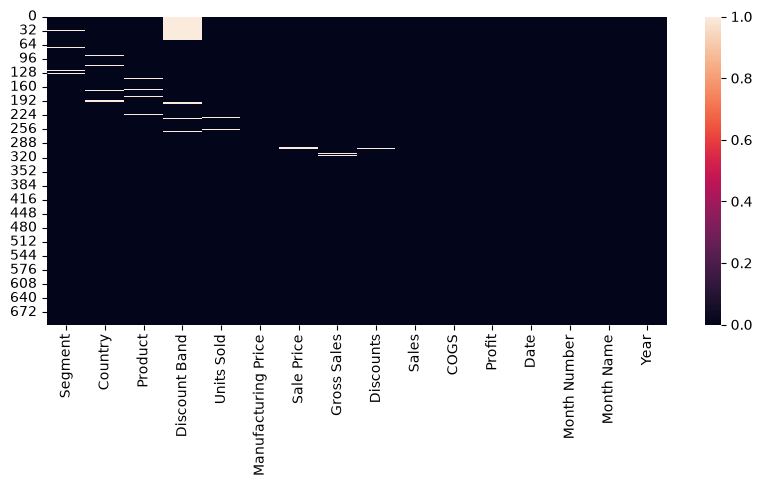

In [91]:
plt.figure(figsize=(10,4))
sns.heatmap(df.isnull())
plt.show

In [92]:
df[' Sales'].sum().sum()

np.float64(118726350.25999999)

In [93]:
df["Country"].value_counts()

Country
France                      139
Mexico                      138
United States of America    138
Canada                      137
Germany                     137
Name: count, dtype: int64

In [94]:
df.groupby("Country").aggregate({"Profit":"sum"})

,Profit
Country,
Canada,3359437.935
France,3781020.780
Germany,3624167.730
Mexico,2889313.870
United States of America,2723336.745


In [95]:
df.groupby("Month Name").aggregate({" Sales":'sum'})

,Sales
Month Name,
April,6964775.07
August,5864622.42
December,17367228.98
February,7297531.39
January,6607761.68
July,8102920.18
June,9518893.82
March,5586859.87
May,6210211.06


In [99]:
df["Country"]=df["Country"].bfill()

In [100]:
df["Country"]=df["Country"].map(lambda val: "USA" if val=="United States of America" else val[:3].upper())

In [101]:
df.head(4)

,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,CAN,Carretera,NaN,1618.5,3,20.0,32370.0,0.0,32370.0,16185.0,16185.0,2014-01-01,1,January,2014
1,Government,GER,Carretera,NaN,1321.0,3,20.0,26420.0,0.0,26420.0,13210.0,13210.0,2014-01-01,1,January,2014
2,Midmarket,FRA,Carretera,NaN,2178.0,3,15.0,32670.0,0.0,32670.0,21780.0,10890.0,2014-06-01,6,June,2014
3,Midmarket,GER,Carretera,NaN,888.0,3,15.0,13320.0,0.0,13320.0,8880.0,4440.0,2014-06-01,6,June,2014


In [102]:
df["Country"]

0      CAN
1      GER
2      FRA
3      GER
4      MEX
      ... 
695    FRA
696    MEX
697    MEX
698    CAN
699    USA
Name: Country, Length: 700, dtype: str

In [103]:
df["Country"].unique()

<ArrowStringArray>
['CAN', 'GER', 'FRA', 'MEX', 'USA']
Length: 5, dtype: str

In [104]:
df["Product"].unique()

<ArrowStringArray>
['Carretera', 'Montana', 'Paseo', 'Velo', 'VTT', 'Amarilla', nan]
Length: 7, dtype: str

In [105]:
for col in df:
    print(col)

Segment
Country
Product
Discount Band
Units Sold
Manufacturing Price
Sale Price
Gross Sales
Discounts
 Sales
COGS
Profit
Date
Month Number
Month Name
Year


In [114]:
for col in df:
    if df[col].isnull().sum()>0:
        print(col,df[col].isnull().sum())

Segment 8
Product 8
Discount Band 62
Units Sold 5
Sale Price 7
Gross Sales 5
Discounts 5


In [116]:
for col in df:
    if df[col].isnull().sum()>0:
        if df[col].dtypes==object:
            print(col)

In [107]:
df.columns

Index(['Segment', 'Country', 'Product', 'Discount Band', 'Units Sold',
       'Manufacturing Price', 'Sale Price', 'Gross Sales', 'Discounts',
       ' Sales', 'COGS', 'Profit', 'Date', 'Month Number', 'Month Name',
       'Year'],
      dtype='str')

In [108]:
df.select_dtypes(include=np.number).columns

Index(['Units Sold', 'Manufacturing Price', 'Sale Price', 'Gross Sales',
       'Discounts', ' Sales', 'COGS', 'Profit', 'Month Number', 'Year'],
      dtype='str')

In [113]:
for col in df.select_dtypes(include=object).columns:
    print(df[col].value_counts())
                


Segment
Government          294
Midmarket           100
Enterprise          100
Small Business      100
Channel Partners     98
Name: count, dtype: int64
Country
MEX    141
USA    141
GER    140
CAN    139
FRA    139
Name: count, dtype: int64
Product
Paseo        202
Velo         108
VTT          108
Montana       93
Carretera     92
Amarilla      89
Name: count, dtype: int64
Discount Band
High      245
Medium    236
Low       157
Name: count, dtype: int64
Month Name
October      140
December     105
June          70
September     70
November      70
January       35
March         35
July          35
August        35
February      35
April         35
May           35
Name: count, dtype: int64


C:\Users\DELL\AppData\Local\Temp\ipykernel_9460\775738361.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=object).columns:


In [117]:
df["Discount Band"].mode()

0    High
Name: Discount Band, dtype: str

In [122]:
df["Discount Band"]=df["Discount Band"].fillna(df["Discount Band"].mode()[0])

In [123]:
df["Discount Band"].isnull().sum()

np.int64(0)

In [130]:
for col in df.columns:
    if df[col].isnull().sum()>0:
        if col.select_dtypes(include=np.num):
        
            print(col,'\t',df[col].isnull().sum(),'\t',df[col].dtype,'\tmean:',round(df[col].mean(),2))

AttributeError: 'str' object has no attribute 'select_dtypes'